In [1]:
import os
import yaml
import uproot
import numpy as np
import pandas as pd
import math
import matplotlib.pyplot as plt


In [2]:
output_dir = '../output/notebooks/prompt_secondary'
if not os.path.exists(output_dir):
    print(f'creating {output_dir}')
    os.makedirs(output_dir)

# Load Skimming Datasets

Load data and MC

In [3]:
data_samples = yaml.safe_load(open('../data/testing_ap.yaml', 'r'))
event_id_ds = [23173002, 23173003] #23173002 = secondary, 23173003 = prompt

sample_MC_ds = uproot.open(data_samples[f'mc-{event_id_ds[0]}'][0])
keys_ds_MC = sample_MC_ds['Ds2PhiPi/DecayTree'].keys()

hlt1_tos_var_ds = [k for k in keys_ds_MC if 'Hlt1' in k and 'TOS' in k]
hlt1_tis_var_ds = [k for k in keys_ds_MC if 'Hlt1' in k and 'TIS' in k]
bkg_ds = ['Ds_BKGCAT']
M_ds = ['Ds_M']           
kin_ds = ['Ds_PT', 'Ds_ETA', 'Ds_MINPT', 'Ds_MAXPT', 'Ds_SUMPT', 'mup_PT', 'mum_PT', 'pi_PT', 'Ds_P']
topo_ds = ['Ds_VCHI2DOF', 'Ds_BPVIPCHI2', 'Ds_BPVVDRHO', 'Ds_BPVIP', 'Ds_LOGBPVIPCHI2', 'Ds_MAXDOCA', 'Ds_MAXSDOCA', 'Ds_BPVFD', 'Ds_DTF_PV_CTAU']
isolation_ds = ['Ds_HEAD_LongTrack_0.5_PTASY', 'Ds_HEAD_LongTrack_0.5_CPT', 'Ds_HEAD_LongTrack_1.0_CMULT', 'Ds_LONGTRACK_ISOLATION_v2_isomin3', 'Ds_LONGTRACK_ISOLATION_v3_isomin3', 'Ds_LONGTRACK_ISOLATION_Run2_mum_MVA', 'Ds_LONGTRACK_ISOLATION_Run2_mup_MVA', 'Ds_LONGTRACK_ISOLATION_mup_MVA', 'Ds_LONGTRACK_ISOLATION_mum_MVA']

variables_ds = hlt1_tos_var_ds + hlt1_tis_var_ds + M_ds + kin_ds + topo_ds + isolation_ds


data_np = uproot.open(data_samples['data-24c4a-mu'][0])['Ds2PhiPi/DecayTree'].arrays(variables_ds, library="np")
df_data_ds = pd.DataFrame(data_np)

data_25_np = uproot.open(data_samples['data-25c4-mu'][0])['Ds2PhiPi/DecayTree'].arrays(variables_ds, library="np")
df_data_ds_25 = pd.DataFrame(data_25_np)

df_mc_ds_list = []
for event in event_id_ds:
    MC_np_ds = uproot.open(data_samples[f'mc-{event}'][0])['Ds2PhiPi/DecayTree'].arrays(variables_ds + bkg_ds, library="np")
    MC_df_ds = pd.DataFrame(MC_np_ds) 
    
    #tag to distinguish prompt and secondary MC
    MC_df_ds['is_prompt'] = 1 if event == 23173003 else 0
    df_mc_ds_list.append(MC_df_ds)
    
df_MC_ds = pd.concat(df_mc_ds_list, ignore_index=True)
df_MC_ds = df_MC_ds[df_MC_ds['Ds_BKGCAT'] <= 50]

Trigger and Pre-selection tags

In [4]:
def trigger_filter(df): 
    if 'Tau_Hlt1DiMuonDisplacedDecision_TOS' in df.columns:
        prefix = 'Tau'
    elif 'Ds_Hlt1DiMuonDisplacedDecision_TOS' in df.columns:
        prefix = 'Ds'
    else:
        raise KeyError("Error")

    col_1 = f'{prefix}_Hlt1DiMuonDisplacedDecision_TOS'
    col_2 = f'{prefix}_Hlt1TwoTrackMVADecision_TOS'

    mask1 = df[col_1].astype(bool)                                                                                                           
    mask2 = df[col_2].astype(bool)
    return df[mask1 | mask2].copy()

df_data_ds = trigger_filter(df_data_ds) 
df_MC_ds = trigger_filter(df_MC_ds)

#selection cut
cut_vchi2 = 6.312
df_MC_ds = df_MC_ds[df_MC_ds['Ds_VCHI2DOF'] < cut_vchi2].copy()
df_data_ds = df_data_ds[df_data_ds['Ds_VCHI2DOF'] < cut_vchi2].copy()

Mass fit and sWeights

[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooRealVar::Ds_M
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooRealVar::sig_mc_m1
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooRealVar::sig_mc_s1
[#0] WARNING:InputArguments -- The parameter 'sig_mc_s1' with range [0, 100] of the RooGaussian 'sig_mc_g1' exceeds the safe range of (0, inf). Advise to limit its range.
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooGaussian::sig_mc_g1
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) using existing copy of RooRealVar::Ds_M for import of RooGaussian::sig_mc_g1
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) using existing copy of RooRealVar::sig_mc_m1 for import of RooGaussian::sig_mc_g1
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) using existing copy of RooRealVar::sig_mc_s1 for import of RooGaussian::sig_mc_g1
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooRealVar::sig_mc_dm
[#1] INF

Info in <Minuit2>: MnSeedGenerator Computing seed using NumericalGradient calculator
Info in <Minuit2>: MnSeedGenerator Evaluated function and gradient in 196.953 ms
Info in <Minuit2>: MnSeedGenerator Initial state: FCN =       267835.5174 Edm =       653.1949862 NCalls =     35
Info in <Minuit2>: MnSeedGenerator Initial state  
  Minimum value : 267835.5174
  Edm           : 653.1949862
  Internal parameters:	[                0                0      0.927295218                0                0     -0.927295218     -0.927295218]	
  Internal gradient  :	[     -325.3225151     -2537.342891       1381.10085      206.7520509      13895.90487      806.2438006     -22910.47387]	
  Internal covariance matrix:
[[  0.00090023071              0              0              0              0              0              0]
 [              0  1.4117026e-05              0              0              0              0              0]
 [              0              0  0.00067088281              0       

ammaJsu for import of RooAddPdf::sig_mc_g1_jsu
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) using existing copy of RooRealVar::sig_mc_deltaJsu for import of RooAddPdf::sig_mc_g1_jsu
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) using existing copy of RooRealVar::sig_mc_fg1 for import of RooAddPdf::sig_mc_g1_jsu
[#1] INFO:Fitting -- RooAbsPdf::fitTo(sig_mc_g1_jsu) fixing normalization set for coefficient determination to observables in data
[#1] INFO:Fitting -- using generic CPU library compiled with no vectorizations
[#1] INFO:Fitting -- Creation of NLL object took 23.1528 ms
[#1] INFO:Fitting -- RooAddition::defaultErrorLevel(nll_sig_mc_g1_jsu_) Summation contains a RooNLLVar, using its error level
[#1] INFO:Minimization -- RooAbsMinimizerFcn::setOptimizeConst: activating const optimization
[#1] INFO:Minimization -- [fitFCN] No discrete parameters, performing continuous minimization only
Minuit2Minimizer: Minimize with max-calls 3500 convergence for edm < 1 strategy 1
M

Info in <Minuit2>: MnSeedGenerator Computing seed using NumericalGradient calculator
Info in <Minuit2>: MnSeedGenerator Evaluated function and gradient in 9.41154 ms
Info in <Minuit2>: MnSeedGenerator Initial state: FCN =      -67967.01912 Edm =     0.04892016442 NCalls =     11
Info in <Minuit2>: MnSeedGenerator Initial state  
  Minimum value : -67967.01912
  Edm           : 0.04892016442
  Internal parameters:	[      1.511472267    -0.6565061505    -0.4002621789    -0.2671669927    -0.4916260696]	
  Internal gradient  :	[     -4.150729686   -0.05385894478    -0.2769744254     -121.0324546      4.129707383]	
  Internal covariance matrix:
[[  0.00050189623              0              0              0              0]
 [              0  0.00012528781              0              0              0]
 [              0              0  0.00012020659              0              0]
 [              0              0              0  1.2634706e-05              0]
 [              0              0    

Fit results saved in ../output/notebooks/prompt_secondary/ds_data_fit_presel.res


Fit Result
Fit status = 0
Minuit status = 3
Number of Loops = 2
Real Time  = 0.1742382049560547
CPU Time  = 0.17999999999999972

  RooFitResult: minimized FCN value: Signal = 9527, Bkg = 6082
-67967.1, estimated distance to minimum: 3.23157e-05
                covariance matrix quality: Full, accurate covariance matrix
                Status : MINIMIZE=0 HESSE=0 

    Constant Parameter    Value     
  --------------------  ------------
       sig_mc_deltaJsu    2.7780e+00
             sig_mc_dm    1.5940e+01
            sig_mc_fg1    6.6394e-02
       sig_mc_gammaJsu    1.9159e-01
            sig_mc_rs2    8.9692e-01

    Floating Parameter  InitialValue    FinalValue +/-  Error     GblCorr.
  --------------------  ------------  --------------------------  --------
                   lam   -8.7965e-04   -8.7958e-04 +/-  4.86e-04  0.219936
                 n_bkg    6.0828e+03    6.0820e+03 +/-  1.23e+02 

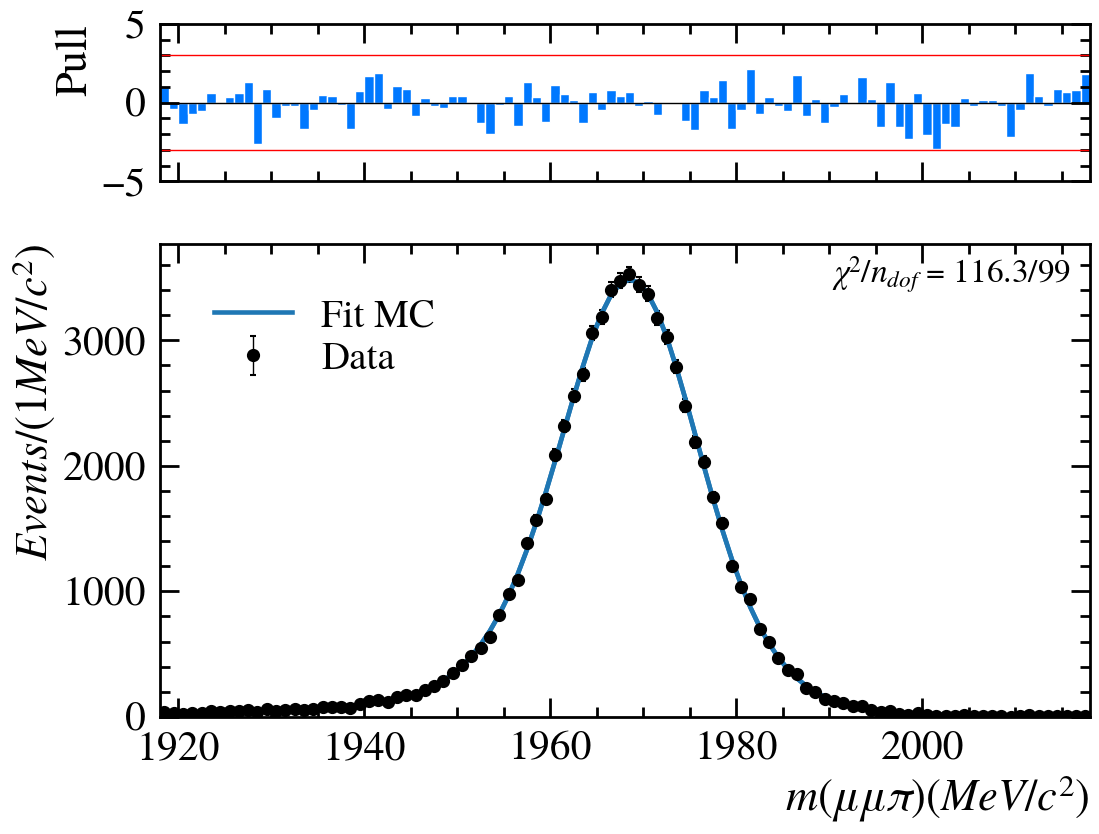

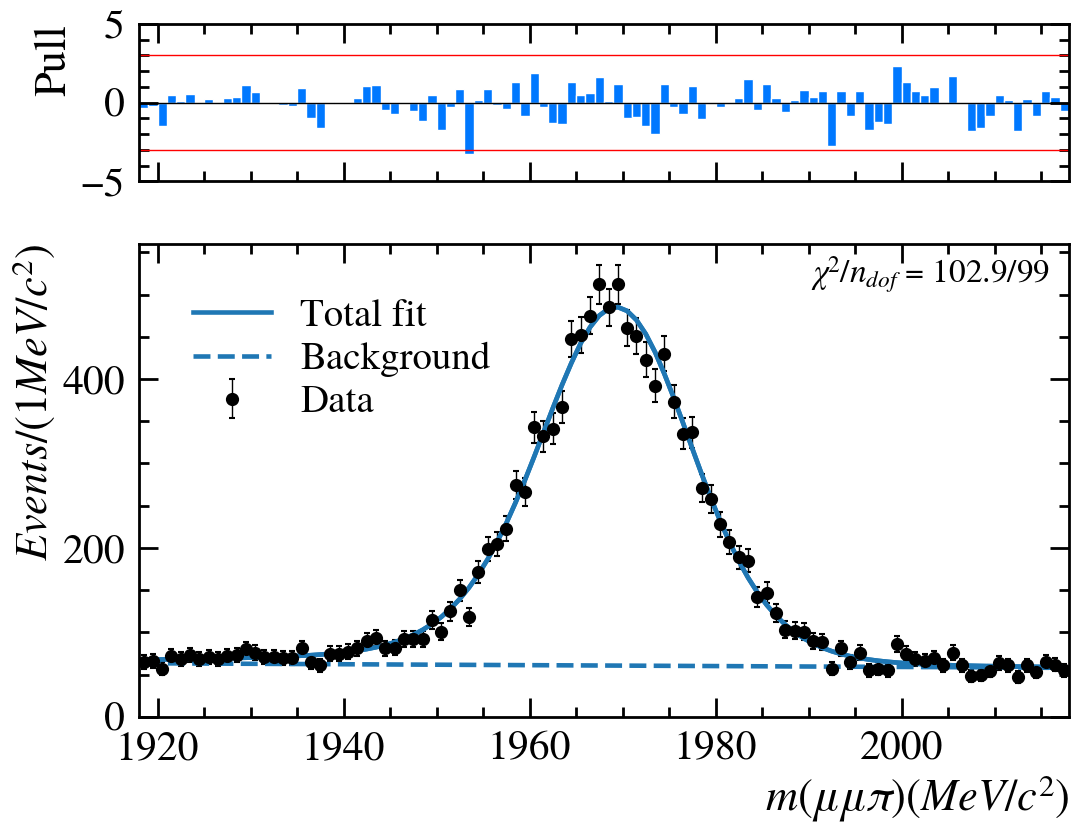

In [5]:
from analysis_helpers.fit import FitModels, FitUtils, add_to_workspace
from analysis_helpers.root_helpers import import_root_with_proxy
import numpy as np

r, _HAS_ROOT = import_root_with_proxy()
fm = FitModels()
fu = FitUtils()

m_min, m_max = 1918, 2018

#MC
mask_mc = (df_MC_ds['Ds_M'] > m_min) & (df_MC_ds['Ds_M'] < m_max)  
m_mc = df_MC_ds.loc[mask_mc, 'Ds_M'].values
#Real Data
mask_data = (df_data_ds['Ds_M'] > m_min) & (df_data_ds['Ds_M'] < m_max)
m_data = df_data_ds.loc[mask_data, 'Ds_M'].values

ws = fm.simple_workspace('Ds_M', m_min, m_max, 'm(#mu#mu#pi)', 'MeV/c^{2}')
Ds_M = ws.var('Ds_M')

data_mc = fu.DatasetFromNumpy(m_mc, Ds_M)
data_real = fu.DatasetFromNumpy(m_data, Ds_M)

# Fit MC
sig_mc = fm.JohnsonPlusGaussian(ws, 'sig_mc', 'Ds_M')

res_mc = fu.fit_to_data(sig_mc, data_mc)
res_mc.Print()

mc_params = sig_mc.getParameters(r.RooArgSet(Ds_M))
for var in mc_params:
    var.setConstant(True)

#plot mc
frame_mc = Ds_M.frame(r.RooFit.Title("Fit MC"))
data_mc.plotOn(frame_mc)
sig_mc.plotOn(frame_mc)
sig_mc.plotOn(frame_mc) 
fig_mc, ax_mc = fu.plot_fit_and_residuals_mpl(frame_mc, labels=['Data', 'Fit MC'])
import matplotlib.ticker as ticker
fig_mc.axes[0].tick_params(axis='x', labelbottom=False)
fig_mc.axes[1].xaxis.set_major_formatter(ticker.ScalarFormatter())
fig_mc.axes[1].tick_params(axis='x', labelbottom=True)

# Fit Data
lam = add_to_workspace(ws, r.RooRealVar('lam', 'lam', -0.001, -1.0, 0.0))
bkg = add_to_workspace(ws, r.RooExponential('bkg', 'bkg', Ds_M, lam))

#Number events variables
n_sig = add_to_workspace(ws, r.RooRealVar('n_sig', 'n_sig', len(m_data)*0.5, 0, len(m_data)*2))
n_bkg = add_to_workspace(ws, r.RooRealVar('n_bkg', 'n_bkg', len(m_data)*0.5, 0, len(m_data)*2))

model_data = add_to_workspace(ws, r.RooAddPdf('model_data', 'model_data', [sig_mc, bkg], [n_sig, n_bkg]))

#free parameters
for p_name in ['sig_mc_m1','sig_mc_s1','lam']: 
    var = ws.var(p_name)
    if var:
        var.setConstant(False)

fu.safe_read_roofit_vars(ws, f'{output_dir}/ds_data_fit_presel.txt')
res_data = fu.fit_to_data(model_data, data_real, outname=f'{output_dir}/ds_data_fit_presel')
ws.allVars().writeToFile(f'{output_dir}/ds_data_fit_presel.txt')
fu.AddFitInfo(f'{output_dir}/ds_data_fit_presel.txt', res_data)
print(f"Signal = {n_sig.getVal():.0f}, Bkg = {n_bkg.getVal():.0f}")

#plot
frame_data = Ds_M.frame(r.RooFit.Title("Fit Data Post-Selection"))
data_real.plotOn(frame_data)
model_data.plotOn(frame_data)
model_data.plotOn(frame_data, r.RooFit.Components("bkg"), r.RooFit.LineStyle(r.kDashed))
model_data.plotOn(frame_data) #for pulls
fig_data, ax_data = fu.plot_fit_and_residuals_mpl(frame_data, labels=['Data', 'Total fit', 'Background'])

import matplotlib.ticker as ticker
fig_data.axes[0].tick_params(axis='x', labelbottom=False)
fig_data.axes[1].xaxis.set_major_formatter(ticker.ScalarFormatter())
fig_data.axes[1].tick_params(axis='x', labelbottom=True)

fig_data.savefig(f'{output_dir}/ds_data_fit_presel.png', dpi=300)

#sWeights
sw = fu.Sweights(ws, 'Ds_M', data_real, model_data.GetName(), 
                 pdfs=[sig_mc.GetName(), bkg.GetName()], nevs=[n_sig.GetName(), n_bkg.GetName()], verbose=False)

#signal weights
sw_sig_list = []

n_events = sw["tree"].GetEntries()
for i in range(n_events):
    sw["tree"].GetEntry(i)                       
    w = sw["vars"]["w_n_sig"][0]               
    sw_sig_list.append(w)                   

sw_sig_np = np.array(sw_sig_list)

df_data_ds['sWeight'] = 0.0
df_data_ds.loc[mask_data, 'sWeight'] = sw_sig_np

## 2025 Dataset

Fit results saved in ../output/notebooks/prompt_secondary/ds_data_fit_presel_25.res


Fit Result
Fit status = 0
Minuit status = 3
Number of Loops = 2
Real Time  = 0.3333890438079834
CPU Time  = 0.33000000000000185
2025 -> Signal = 3810, Bkg = 24971
Running fit in "Silent" mode
w_n_sig_25 array('f', [0.0]) 0.0 float f
w_n_bkg_25 array('f', [0.0]) 0.0 float f
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooRealVar::lam_25
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooExponential::bkg_25
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) using existing copy of RooRealVar::Ds_M for import of RooExponential::bkg_25
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) using existing copy of RooRealVar::lam_25 for import of RooExponential::bkg_25
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooRealVar::n_sig_25
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooRealVar::n_bkg_25
[#1] INFO:ObjectHandling -- RooWorkspace::

Info in <Minuit2>: MnSeedGenerator Computing seed using NumericalGradient calculator
Info in <Minuit2>: MnSeedGenerator Evaluated function and gradient in 23.1121 ms
Info in <Minuit2>: MnSeedGenerator Initial state: FCN =      -134607.2349 Edm =    0.004706209486 NCalls =     17
Info in <Minuit2>: MnSeedGenerator Initial state  
  Minimum value : -134607.2349
  Edm           : 0.004706209486
  Internal parameters:	[      1.497686955    -0.1327991328     -1.050378918    -0.3005022635    -0.4175257534]	
  Internal gradient  :	[     -4.049891298    -0.4163294097    -0.9130317275     -10.81024158     0.5456727492]	
  Internal covariance matrix:
[[  7.3630277e-05              0              0              0              0]
 [              0   6.900514e-05              0              0              0]
 [              0              0  0.00013570699              0              0]
 [              0              0              0  0.00014668538              0]
 [              0              0   

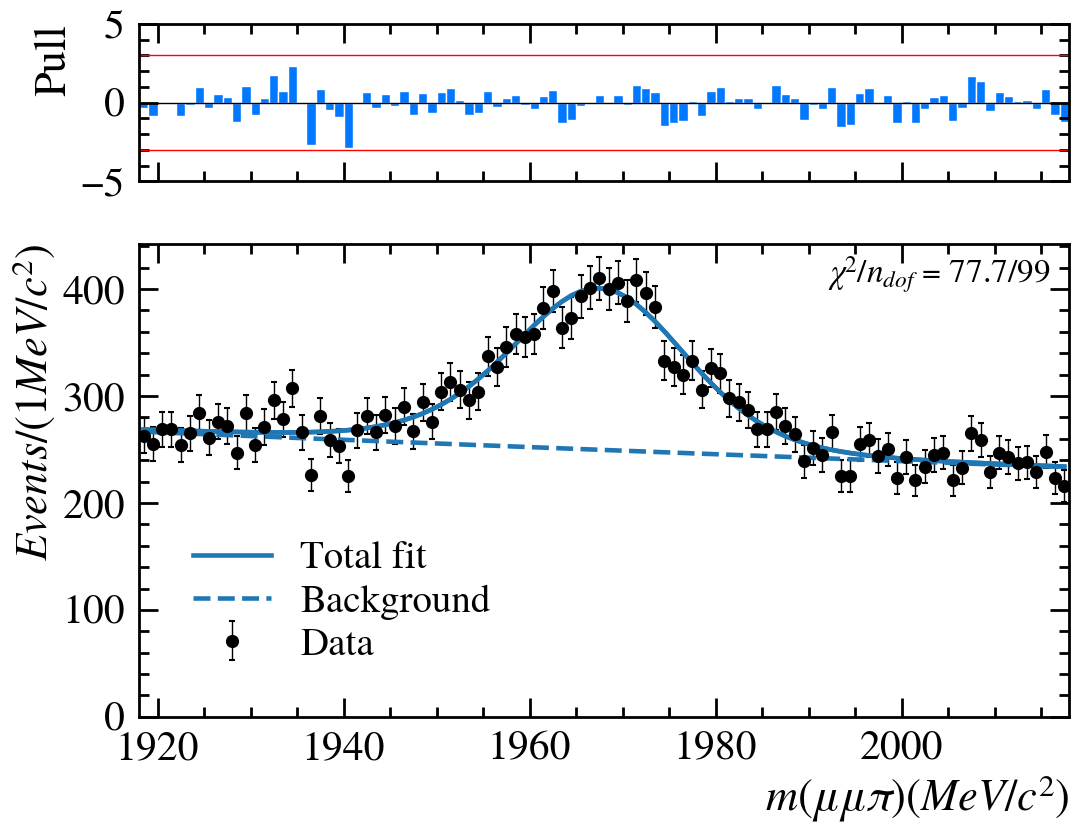

In [6]:
#datasets
df_data_ds_25 = trigger_filter(df_data_ds_25)
df_data_ds_25 = df_data_ds_25[df_data_ds_25['Ds_VCHI2DOF'] < cut_vchi2].copy()

mask_data_25 = (df_data_ds_25['Ds_M'] > m_min) & (df_data_ds_25['Ds_M'] < m_max)
m_data_25 = df_data_ds_25.loc[mask_data_25, 'Ds_M'].values
data_real_25 = fu.DatasetFromNumpy(m_data_25, Ds_M)

#model 
lam_25 = add_to_workspace(ws, r.RooRealVar('lam_25', 'lam_25', -0.001, -1.0, 0.0))
bkg_25 = add_to_workspace(ws, r.RooExponential('bkg_25', 'bkg_25', Ds_M, lam_25))

n_sig_25 = add_to_workspace(ws, r.RooRealVar('n_sig_25', 'n_sig_25', len(m_data_25)*0.5, 0, len(m_data_25)*2))
n_bkg_25 = add_to_workspace(ws, r.RooRealVar('n_bkg_25', 'n_bkg_25', len(m_data_25)*0.5, 0, len(m_data_25)*2))

model_data_25 = add_to_workspace(ws, r.RooAddPdf('model_data_25', 'model_data_25', [sig_mc, bkg_25], [n_sig_25, n_bkg_25]))

for p_name in ['sig_mc_m1', 'sig_mc_s1']: 
    var = ws.var(p_name)
    if var:
        var.setConstant(False)

#fit
fu.safe_read_roofit_vars(ws, f'{output_dir}/ds_data_fit_presel_25.txt')
res_data_25 = fu.fit_to_data(model_data_25, data_real_25, outname=f'{output_dir}/ds_data_fit_presel_25')
ws.allVars().writeToFile(f'{output_dir}/ds_data_fit_presel_25.txt')
fu.AddFitInfo(f'{output_dir}/ds_data_fit_presel_25.txt', res_data_25)
print(f"2025 -> Signal = {n_sig_25.getVal():.0f}, Bkg = {n_bkg_25.getVal():.0f}")

#plot
frame_data_25 = Ds_M.frame(r.RooFit.Title("Fit Data 2025 Post-Selection"))
data_real_25.plotOn(frame_data_25)
model_data_25.plotOn(frame_data_25)
model_data_25.plotOn(frame_data_25, r.RooFit.Components("bkg_25"), r.RooFit.LineStyle(r.kDashed))
model_data_25.plotOn(frame_data_25) 
fig_data_25, ax_data_25 = fu.plot_fit_and_residuals_mpl(frame_data_25, labels=['Data', 'Total fit', 'Background'])

fig_data_25.axes[0].tick_params(axis='x', labelbottom=False)
fig_data_25.axes[1].xaxis.set_major_formatter(ticker.ScalarFormatter())
fig_data_25.axes[1].tick_params(axis='x', labelbottom=True)
fig_data_25.savefig(f'{output_dir}/ds_data_fit_presel_25.png', dpi=300)

#sweights
sw_25 = fu.Sweights(ws, 'Ds_M', data_real_25, model_data_25.GetName(), 
                 pdfs=[sig_mc.GetName(), bkg_25.GetName()], nevs=[n_sig_25.GetName(), n_bkg_25.GetName()], verbose=False)

sw_sig_list_25 = []
n_events_25 = sw_25["tree"].GetEntries()
for i in range(n_events_25):
    sw_25["tree"].GetEntry(i)                       
    w = sw_25["vars"]["w_n_sig_25"][0]               
    sw_sig_list_25.append(w)                   

sw_sig_np_25 = np.array(sw_sig_list_25)

df_data_ds_25['sWeight'] = 0.0
df_data_ds_25.loc[mask_data_25, 'sWeight'] = sw_sig_np_25

# Prompt and secondary

In [7]:
var_name = 'Ds_LOGBPVIPCHI2'
v_min, v_max = -6.0, 2.77 

ws_ip = fm.SimpleWorkspace(obsname=var_name, xmin=v_min, xmax=v_max, title='LOGBPVIPCHI2', unit='')
log_ip = ws_ip.var(var_name)

df_mc_fit = df_MC_ds[(df_MC_ds[var_name] >= v_min) & (df_MC_ds[var_name] <= v_max)]
df_data_fit = df_data_ds[(df_data_ds[var_name] >= v_min) & (df_data_ds[var_name] <= v_max)]

#MC Prompt, Secondary e Tot
vals_mcp = df_mc_fit.loc[df_mc_fit['is_prompt'] == 1, var_name].values
data_mcp = fu.DatasetFromNumpy(vals_mcp, log_ip)

vals_mcs = df_mc_fit.loc[df_mc_fit['is_prompt'] == 0, var_name].values
data_mcs = fu.DatasetFromNumpy(vals_mcs, log_ip)

vals_mc_tot = df_mc_fit[var_name].values
data_mc_tot = fu.DatasetFromNumpy(vals_mc_tot, log_ip)

#Real-Data sWeighted
weight_var = r.RooRealVar("sWeight", "sWeight", -100, 100)
data_sweight = r.RooDataSet("data_sweight", "data_sweight", r.RooArgSet(log_ip, weight_var), r.RooFit.WeightVar("sWeight"))

for val, w in zip(df_data_fit[var_name].values, df_data_fit['sWeight'].values):
    log_ip.setVal(val)
    weight_var.setVal(w)
    data_sweight.add(r.RooArgSet(log_ip, weight_var), w)

[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooRealVar::Ds_LOGBPVIPCHI2


Fit on MC to fix the shape Johnson

Fit results saved in ../output/notebooks/prompt_secondary/prompt_mc_fit.res


Fit Result
Fit status = 0
Minuit status = 3
Number of Loops = 2
Real Time  = 0.590864896774292
CPU Time  = 0.5899999999999999


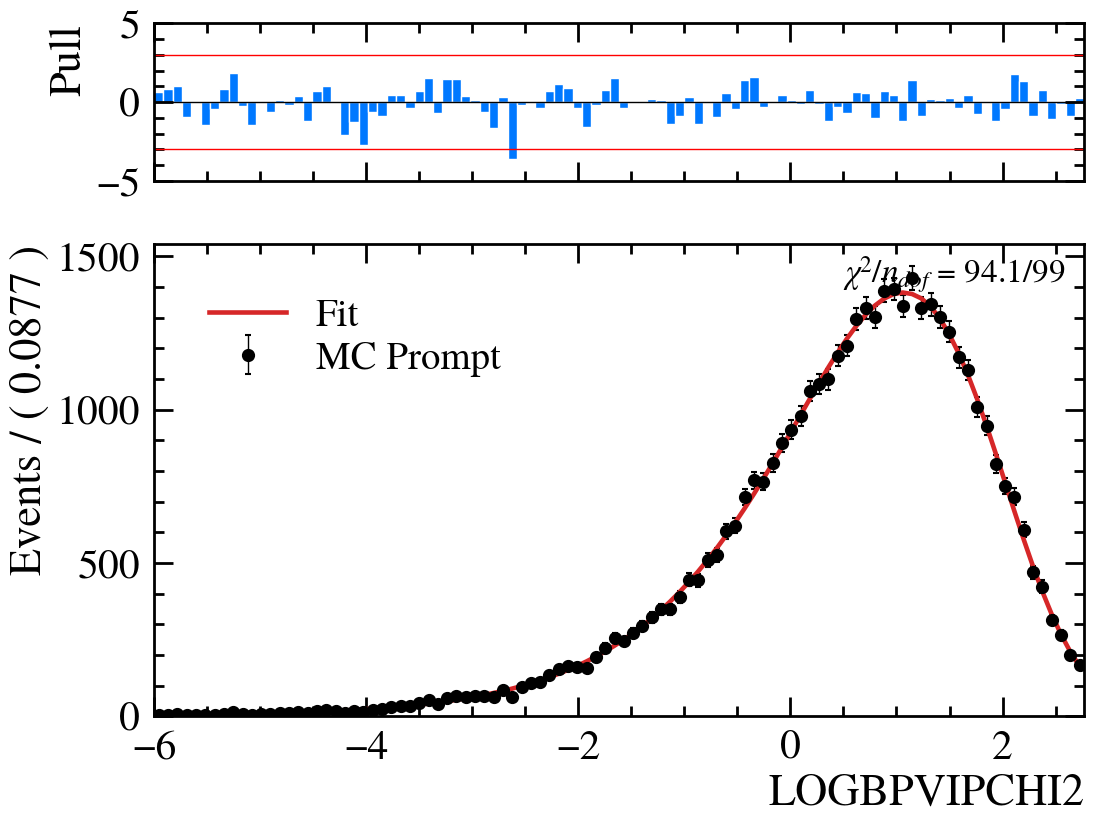

[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooRealVar::prompt_mc_mJsu
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooRealVar::prompt_mc_sJsu
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooRealVar::prompt_mc_gammaJsu
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooRealVar::prompt_mc_deltaJsu
[#0] WARNING:InputArguments -- The parameter 'prompt_mc_sJsu' with range [0, 8.77] of the RooJohnson 'prompt_mc_jsu' exceeds the safe range of (0, inf). Advise to limit its range.
[#0] WARNING:InputArguments -- The parameter 'prompt_mc_deltaJsu' with range [0, 5] of the RooJohnson 'prompt_mc_jsu' exceeds the safe range of (0, inf). Advise to limit its range.
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooJohnson::prompt_mc_jsu
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) using existing copy of RooRealVar::Ds_LOGBPVIPCHI2 for import of RooJohnson::prompt_mc_jsu
[#1] INFO:ObjectHandling -- RooWorkspa

Info in <Minuit2>: MnSeedGenerator Computing seed using NumericalGradient calculator
Info in <Minuit2>: MnSeedGenerator Evaluated function and gradient in 83.4982 ms
Info in <Minuit2>: MnSeedGenerator Initial state: FCN =       67802.96681 Edm =   0.0001173698702 NCalls =     25
Info in <Minuit2>: MnSeedGenerator Initial state  
  Minimum value : 67802.96681
  Edm           : 0.0001173698702
  Internal parameters:	[    -0.5460073962     0.2572892821     0.6987136938    -0.7109746155]	
  Internal gradient  :	[       8.25255879     -15.31443046      2.726600248     -6.970076294]	
  Internal covariance matrix:
[[  1.7984817e-06              0              0              0]
 [              0  5.3255787e-07              0              0]
 [              0              0  1.1749154e-05              0]
 [              0              0              0  2.7735667e-06]]]
Info in <Minuit2>: VariableMetricBuilder Start iterating until Edm is < 0.001 with call limit = 2000
Info in <Minuit2>: Variabl

In [8]:
#FITTING MC PROMPT 
pdf_prompt_mc = fm.Johnson(ws_ip, 'prompt_mc', var_name)
ws_ip.var('prompt_mc_mJsu').setRange(-2.0, 4.0)
ws_ip.var('prompt_mc_sJsu').setRange(0.01, 10.0)
ws_ip.var('prompt_mc_gammaJsu').setRange(-10.0, 10.0)
ws_ip.var('prompt_mc_deltaJsu').setRange(0.01, 10.0)
ws_ip.var('prompt_mc_mJsu').setVal(1.0)

fu.safe_read_roofit_vars(ws_ip, f'{output_dir}/prompt_mc_fit.txt')
res_prompt = fu.fit_to_data(pdf_prompt_mc, data_mcp, kSilent=False, outname=f'{output_dir}/prompt_mc_fit')

#plot
frame_p = log_ip.frame(r.RooFit.Title(""))
data_mcp.plotOn(frame_p)
pdf_prompt_mc.plotOn(frame_p, r.RooFit.LineColor(r.kRed))
fig_p, ax_p = fu.plot_fit_and_residuals_mpl(frame_p, labels=['MC Prompt', 'Fit']) 

import matplotlib.ticker as ticker
fig_p.axes[0].tick_params(axis='x', labelbottom=False)
fig_p.axes[1].xaxis.set_major_formatter(ticker.ScalarFormatter())
fig_p.axes[1].tick_params(axis='x', labelbottom=True)

fig_p.savefig(f'{output_dir}/prompt_mc_fit.png', dpi=300)
ws_ip.allVars().writeToFile(f'{output_dir}/prompt_mc_fit.txt')
fu.AddFitInfo(f'{output_dir}/prompt_mc_fit.txt', res_prompt)
plt.show()

for p in ['prompt_mc_gammaJsu', 'prompt_mc_deltaJsu', 'prompt_mc_mJsu', 'prompt_mc_sJsu']:
    ws_ip.var(p).setConstant(True)

Fit results saved in ../output/notebooks/prompt_secondary/sec_mc_fit.res


Fit Result
Fit status = 1
Minuit status = 2
Number of Loops = 21
Real Time  = 4.07067608833313
CPU Time  = 4.060000000000002


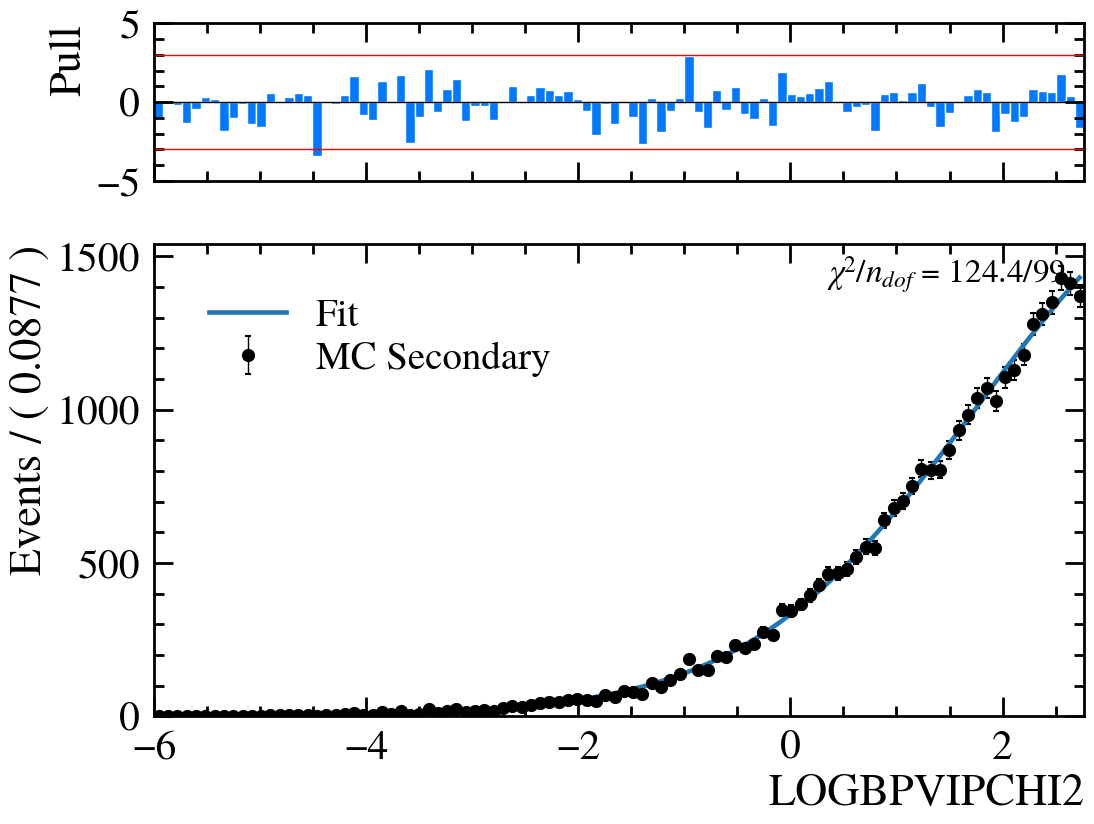

[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooRealVar::sec_mc_mJsu
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooRealVar::sec_mc_sJsu
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooRealVar::sec_mc_gammaJsu
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooRealVar::sec_mc_deltaJsu
[#0] WARNING:InputArguments -- The parameter 'sec_mc_sJsu' with range [0, 8.77] of the RooJohnson 'sec_mc_jsu' exceeds the safe range of (0, inf). Advise to limit its range.
[#0] WARNING:InputArguments -- The parameter 'sec_mc_deltaJsu' with range [0, 5] of the RooJohnson 'sec_mc_jsu' exceeds the safe range of (0, inf). Advise to limit its range.
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooJohnson::sec_mc_jsu
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) using existing copy of RooRealVar::Ds_LOGBPVIPCHI2 for import of RooJohnson::sec_mc_jsu
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) using existing 

Info in <Minuit2>: MnSeedGenerator Computing seed using NumericalGradient calculator
Info in <Minuit2>: MnSeedGenerator Evaluated function and gradient in 44.5466 ms
Info in <Minuit2>: MnSeedGenerator Initial state: FCN =       42056.25817 Edm =    0.001684128438 NCalls =     19
Info in <Minuit2>: MnSeedGenerator Initial state  
  Minimum value : 42056.25817
  Edm           : 0.001684128438
  Internal parameters:	[    -0.6533222215    -0.1553612415     -1.534279461   -0.00442443886]	
  Internal gradient  :	[     -1.058598063      3.026526769     0.2495001311     0.4375380032]	
  Internal covariance matrix:
[[  1.9071103e-05              0              0              0]
 [              0  3.0714773e-06              0              0]
 [              0              0     0.10715933              0]
 [              0              0              0  8.5175319e-05]]]
Info in <Minuit2>: VariableMetricBuilder Start iterating until Edm is < 0.001 with call limit = 2000
Info in <Minuit2>: Variable

In [9]:
# FITTING MC SECONDARY
pdf_sec_mc = fm.Johnson(ws_ip, 'sec_mc', var_name)

ws_ip.var('sec_mc_mJsu').setRange(1.0, 7.0)
ws_ip.var('sec_mc_sJsu').setRange(0.01, 10.0)
ws_ip.var('sec_mc_gammaJsu').setRange(-10.0, 10.0)
ws_ip.var('sec_mc_deltaJsu').setRange(0.01, 10.0)
ws_ip.var('sec_mc_mJsu').setVal(4.5)

fu.safe_read_roofit_vars(ws_ip, f'{output_dir}/sec_mc_fit.txt')
res_sec = fu.fit_to_data(pdf_sec_mc, data_mcs, kSilent=False, outname=f'{output_dir}/sec_mc_fit')

#plot
frame_s = log_ip.frame(r.RooFit.Title(""))
data_mcs.plotOn(frame_s)
pdf_sec_mc.plotOn(frame_s, r.RooFit.LineColor(r.kBlue))
fig_s, ax_s = fu.plot_fit_and_residuals_mpl(frame_s, labels=['MC Secondary', 'Fit']) 

import matplotlib.ticker as ticker
fig_s.axes[0].tick_params(axis='x', labelbottom=False)
fig_s.axes[1].xaxis.set_major_formatter(ticker.ScalarFormatter())
fig_s.axes[1].tick_params(axis='x', labelbottom=True)

fig_s.savefig(f'{output_dir}/sec_mc_fit.png', dpi=300)
ws_ip.allVars().writeToFile(f'{output_dir}/sec_mc_fit.txt')
fu.AddFitInfo(f'{output_dir}/sec_mc_fit.txt', res_sec)

plt.show()

for p in ['sec_mc_gammaJsu', 'sec_mc_deltaJsu', 'sec_mc_mJsu', 'sec_mc_sJsu']:
    ws_ip.var(p).setConstant(True)

Fit combined on MC 

Fit results saved in ../output/notebooks/prompt_secondary/tot_mc_fit.res


Fit Result
Fit status = 0
Minuit status = 3
Number of Loops = 2
Real Time  = 0.06184697151184082
CPU Time  = 0.05999999999999517


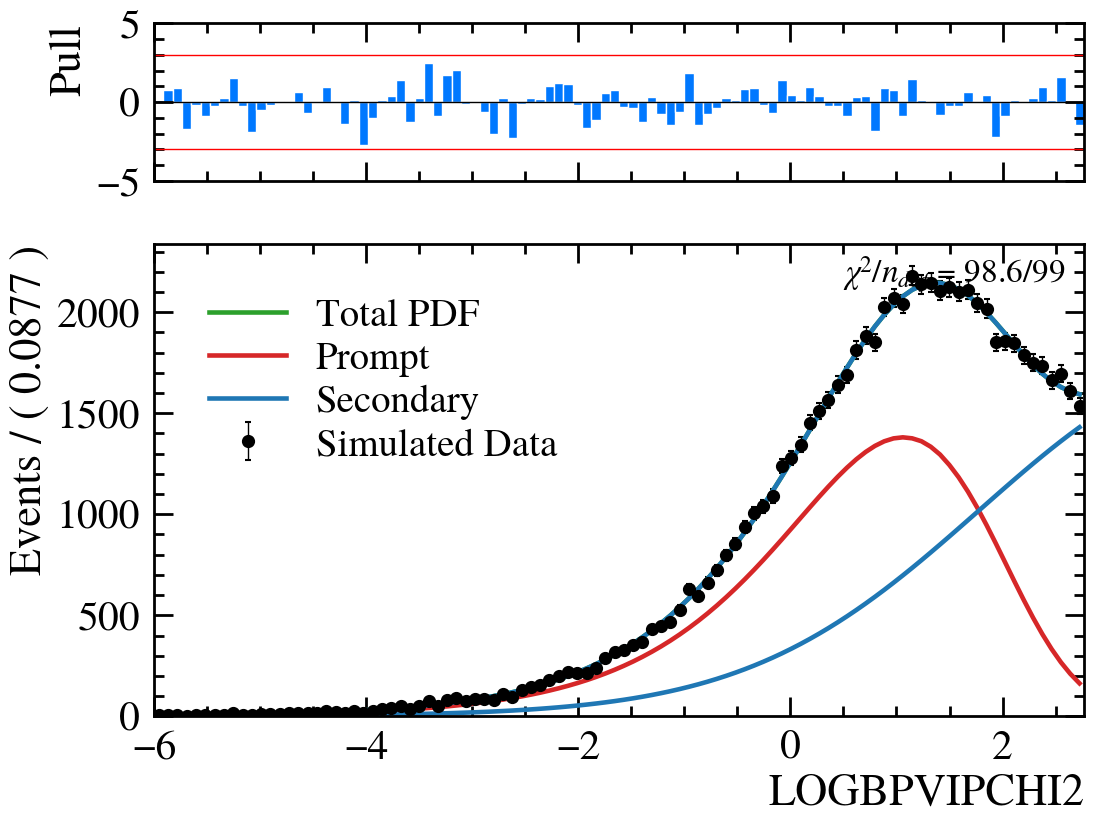

[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooRealVar::frac_prompt_mc
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooAddPdf::model_mc_tot
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) using existing copy of RooJohnson::prompt_mc_jsu for import of RooAddPdf::model_mc_tot
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) using existing copy of RooRealVar::Ds_LOGBPVIPCHI2 for import of RooAddPdf::model_mc_tot
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) using existing copy of RooRealVar::prompt_mc_mJsu for import of RooAddPdf::model_mc_tot
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) using existing copy of RooRealVar::prompt_mc_sJsu for import of RooAddPdf::model_mc_tot
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) using existing copy of RooRealVar::prompt_mc_gammaJsu for import of RooAddPdf::model_mc_tot
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) using existing copy of RooRealVar::prompt_mc_deltaJsu for imp

Info in <Minuit2>: MnSeedGenerator Computing seed using NumericalGradient calculator
Info in <Minuit2>: MnSeedGenerator Evaluated function and gradient in 12.5863 ms
Info in <Minuit2>: MnSeedGenerator Initial state: FCN =        115709.957 Edm =    1.20862014e-07 NCalls =      3
Info in <Minuit2>: MnSeedGenerator Initial state  
  Minimum value : 115709.957
  Edm           : 1.20862014e-07
  Internal parameters:	[     0.1621698855]	
  Internal gradient  :	[   -0.05226575403]	
  Internal covariance matrix:
[[  0.00017697641]]]
Info in <Minuit2>: VariableMetricBuilder Start iterating until Edm is < 0.001 with call limit = 500
Info in <Minuit2>: VariableMetricBuilder    0 - FCN =        115709.957 Edm =    1.20862014e-07 NCalls =      3
Info in <Minuit2>: VariableMetricBuilder    1 - FCN =        115709.957 Edm =   5.588323225e-10 NCalls =      8
Info in <Minuit2>: MnHesse Done after 6.33739 ms
Info in <Minuit2>: VariableMetricBuilder After Hessian
Info in <Minuit2>: VariableMetricBuilder

In [10]:
frac_prompt_mc = add_to_workspace(ws_ip, r.RooRealVar("frac_prompt_mc", "frac_prompt_mc", 0.7, 0.0, 1.0))
model_mc_tot = add_to_workspace(ws_ip, r.RooAddPdf("model_mc_tot", "Total MC PDF", [pdf_prompt_mc, pdf_sec_mc], [frac_prompt_mc]))

fu.safe_read_roofit_vars(ws_ip, f'{output_dir}/tot_mc_fit.txt')
res_mc_tot = fu.fit_to_data(model_mc_tot, data_mc_tot, kSilent=False, outname=f'{output_dir}/tot_mc_fit')

#plot MC
frame_mc = log_ip.frame(r.RooFit.Title(""))
data_mc_tot.plotOn(frame_mc)
model_mc_tot.plotOn(frame_mc, r.RooFit.LineColor(r.kGreen))
model_mc_tot.plotOn(frame_mc, r.RooFit.Components("prompt_mc_jsu"), r.RooFit.LineColor(r.kRed))
model_mc_tot.plotOn(frame_mc, r.RooFit.Components("sec_mc_jsu"), r.RooFit.LineColor(r.kBlue))
model_mc_tot.plotOn(frame_mc) 
fig_mc, ax_mc = fu.plot_fit_and_residuals_mpl(frame_mc, labels=['Simulated Data', 'Total PDF', 'Prompt', 'Secondary'])

import matplotlib.ticker as ticker
fig_mc.axes[0].tick_params(axis='x', labelbottom=False)
fig_mc.axes[1].xaxis.set_major_formatter(ticker.ScalarFormatter())
fig_mc.axes[1].tick_params(axis='x', labelbottom=True)

fig_mc.savefig(f'{output_dir}/tot_mc_fit.png', dpi=300)
ws_ip.allVars().writeToFile(f'{output_dir}/tot_mc_fit.txt')
fu.AddFitInfo(f'{output_dir}/tot_mc_fit.txt', res_mc_tot)
plt.show()

Fit on data sweighted

    invalid_argument: Conversion to floating point failed
Falling back to python parsing of the file, which may be less robust to changes in the format of the output.
Fit results saved in ../output/notebooks/prompt_secondary/tot_data_fit.res


Fit Result
Fit status = 0
Minuit status = 3
Number of Loops = 2
Real Time  = 0.21190905570983887
CPU Time  = 0.19999999999999574


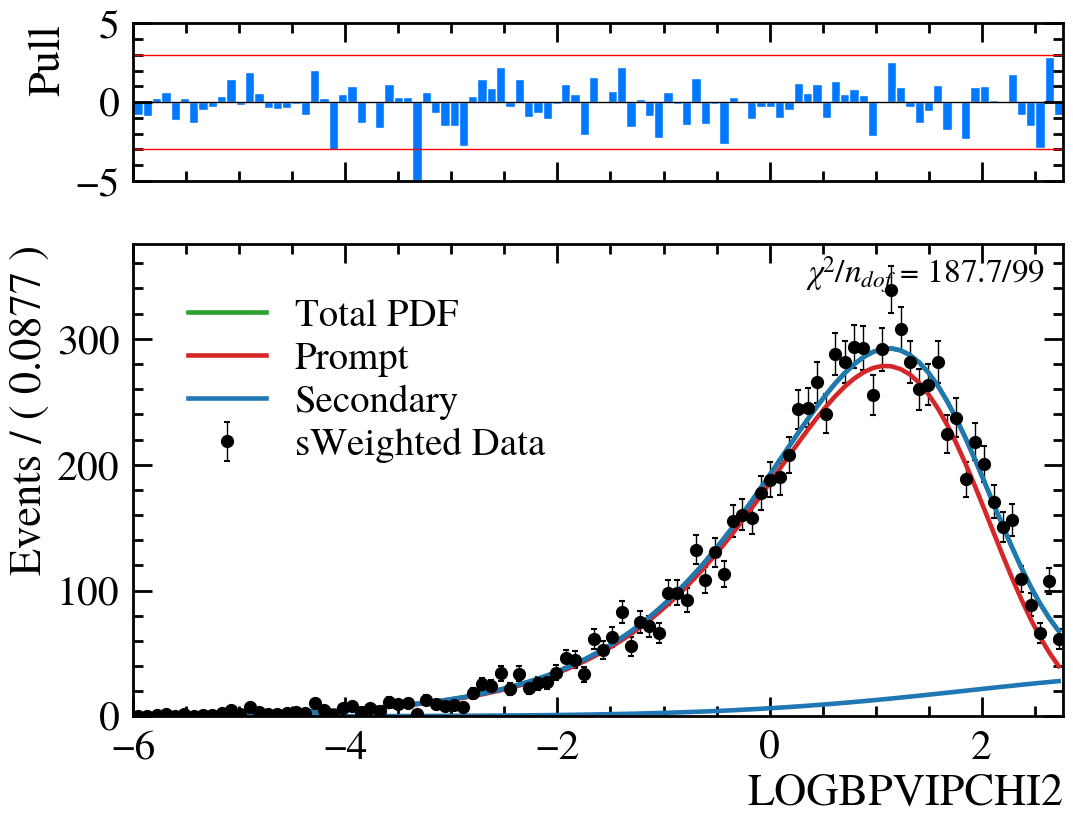

[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooRealVar::c_sigma
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooRealVar::delta_mu
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooRealVar::data_mu_P
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooFormulaVar::data_lam_P
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) using existing copy of RooRealVar::prompt_mc_sJsu for import of RooFormulaVar::data_lam_P
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) using existing copy of RooRealVar::c_sigma for import of RooFormulaVar::data_lam_P
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooJohnson::pdf_prompt_data
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) using existing copy of RooRealVar::Ds_LOGBPVIPCHI2 for import of RooJohnson::pdf_prompt_data
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) using existing copy of RooRealVar::data_mu_P for import of RooJohnson::pdf_prompt_data
[#1

Info in <Minuit2>: MnSeedGenerator Computing seed using NumericalGradient calculator
Info in <Minuit2>: MnSeedGenerator Evaluated function and gradient in 22.9723 ms
Info in <Minuit2>: MnSeedGenerator Initial state: FCN =       15057.06796 Edm =    8.64553363e-06 NCalls =     13
Info in <Minuit2>: MnSeedGenerator Initial state  
  Minimum value : 15057.06796
  Edm           : 8.64553363e-06
  Internal parameters:	[    -0.3108485894     0.7298171025      1.059477648]	
  Internal gradient  :	[    -0.3913744602       0.31974573   -0.04580267458]	
  Internal covariance matrix:
[[  0.00013146969              0              0]
 [              0  7.3409429e-05              0]
 [              0              0   0.0033077202]]]
Info in <Minuit2>: VariableMetricBuilder Start iterating until Edm is < 0.001 with call limit = 1500
Info in <Minuit2>: VariableMetricBuilder    0 - FCN =       15057.06796 Edm =    8.64553363e-06 NCalls =     13
Info in <Minuit2>: VariableMetricBuilder    1 - FCN =     

In [11]:
c_sigma = add_to_workspace(ws_ip, r.RooRealVar("c_sigma", "c_sigma", 1.0, 0.5, 2.0))

# Calculated the difference between the means of the secondary and prompt MC distributions
diff_mu_val = ws_ip.var('sec_mc_mJsu').getVal() - ws_ip.var('prompt_mc_mJsu').getVal()
delta_mu = add_to_workspace(ws_ip, r.RooRealVar("delta_mu", "delta_mu", diff_mu_val))
delta_mu.setConstant(True)

# PDF for prompt 
data_mu_P = add_to_workspace(ws_ip, r.RooRealVar("data_mu_P", 
                                                 "data_mu_P", 
                                                 ws_ip.var('prompt_mc_mJsu').getVal(), 
                                                 -2.0, 4.0))
data_lam_P = add_to_workspace(ws_ip, r.RooFormulaVar("data_lam_P", 
                                                     "@0*@1",
                                                       r.RooArgList(ws_ip.var('prompt_mc_sJsu'),
                                                                     c_sigma)))

pdf_prompt_data = add_to_workspace(ws_ip, r.RooJohnson("pdf_prompt_data", 
                                                       "Prompt Data PDF", 
                                                        log_ip,
                                                        data_mu_P,
                                                        data_lam_P, 
                                                        ws_ip.var('prompt_mc_gammaJsu'),
                                                        ws_ip.var('prompt_mc_deltaJsu')))

# PDF for secondary (data_mu_S depends on data_mu_P and delta_mu)
data_mu_S = add_to_workspace(ws_ip, r.RooFormulaVar("data_mu_S",
                                                    "@0+@1",
                                                    r.RooArgList(data_mu_P, delta_mu)))

data_lam_S = add_to_workspace(ws_ip, r.RooFormulaVar("data_lam_S", 
                                                     "@0*@1", 
                                                     r.RooArgList(ws_ip.var('sec_mc_sJsu'), c_sigma)))

pdf_sec_data = add_to_workspace(ws_ip, r.RooJohnson("pdf_sec_data",
                                                     "Secondary Data PDF", 
                                                     log_ip,
                                                       data_mu_S, 
                                                       data_lam_S, 
                                                       ws_ip.var('sec_mc_gammaJsu'), 
                                                       ws_ip.var('sec_mc_deltaJsu')))

# model tot
frac_prompt_data = add_to_workspace(ws_ip, r.RooRealVar("frac_prompt_data", 
                                                        "frac_prompt_data",
                                                          0.75, 0.0, 1.0))

model_data_tot = add_to_workspace(ws_ip, r.RooAddPdf("model_data_tot",
                                                      "Total Data PDF", 
                                                      [pdf_prompt_data, pdf_sec_data], [frac_prompt_data]))

# Fit data
fu.safe_read_roofit_vars(ws_ip, f'{output_dir}/tot_data_fit.txt')
res_data_ip = fu.fit_to_data(model_data_tot, data_sweight, kSilent=False, outname=f'{output_dir}/tot_data_fit')

# plot
frame_data = log_ip.frame(r.RooFit.Title(""))
data_sweight.plotOn(frame_data, r.RooFit.DataError(r.RooAbsData.SumW2))
model_data_tot.plotOn(frame_data, r.RooFit.LineColor(r.kGreen))
model_data_tot.plotOn(frame_data, r.RooFit.Components("pdf_prompt_data"), r.RooFit.LineColor(r.kRed))
model_data_tot.plotOn(frame_data, r.RooFit.Components("pdf_sec_data"), r.RooFit.LineColor(r.kBlue))
model_data_tot.plotOn(frame_data) 
fig_data, ax_data = fu.plot_fit_and_residuals_mpl(frame_data, labels=['sWeighted Data', 'Total PDF', 'Prompt', 'Secondary'])

import matplotlib.ticker as ticker
fig_data.axes[0].tick_params(axis='x', labelbottom=False)
fig_data.axes[1].xaxis.set_major_formatter(ticker.ScalarFormatter())
fig_data.axes[1].tick_params(axis='x', labelbottom=True)


fig_data.savefig(f'{output_dir}/tot_data_fit.png', dpi=300)
ws_ip.allVars().writeToFile(f'{output_dir}/tot_data_fit.txt')
fu.AddFitInfo(f'{output_dir}/tot_data_fit.txt', res_data_ip)
plt.show()

In [12]:
#summury table
n_prompt_mc = len(vals_mcp)
n_sec_mc = len(vals_mcs)
wfraction_initial = n_prompt_mc / (n_prompt_mc + n_sec_mc)

table_data = {
    'wfraction (%)': [f"{wfraction_initial*100}"],
    'MC fit (%)': [f"{frac_prompt_mc.getVal()*100:.2f} ± {frac_prompt_mc.getError()*100:.2f}"],
    'Data fit (%)': [f"{frac_prompt_data.getVal()*100:.2f} ± {frac_prompt_data.getError()*100:.2f}"]
}

df_table21 = pd.DataFrame(table_data)

display(df_table21)
print(f"Correction factor from Data fit (c_sigma): {c_sigma.getVal():.3f} ± {c_sigma.getError():.3f}")

,wfraction (%),MC fit (%),Data fit (%)
0,58.11002733265448,58.07 ± 0.46,93.60 ± 2.27


Correction factor from Data fit (c_sigma): 1.021 ± 0.014


## 2025 Dataset

Fit Result
Fit status = 0
Minuit status = 3
Number of Loops = 2
Real Time  = 0.20551109313964844
CPU Time  = 0.21000000000000085


/user/gr1/lhcb/limpicciche/tesi_impicciche/tesi-env/lib/python3.11/site-packages/analysis_helpers/fit.py:819: RuntimeWarning: invalid value encountered in sqrt
  mplhep.histplot(his,yerr=np.sqrt(his[0]),histtype='errorbar',color='black',label='data' if labels is None else labels[0],ax=ax2)
/user/gr1/lhcb/limpicciche/tesi_impicciche/tesi-env/lib/python3.11/site-packages/analysis_helpers/fit.py:759: RuntimeWarning: invalid value encountered in sqrt
  data_err = np.sqrt(data_counts) if poisson else np.sqrt(data_counts) # to be fixed


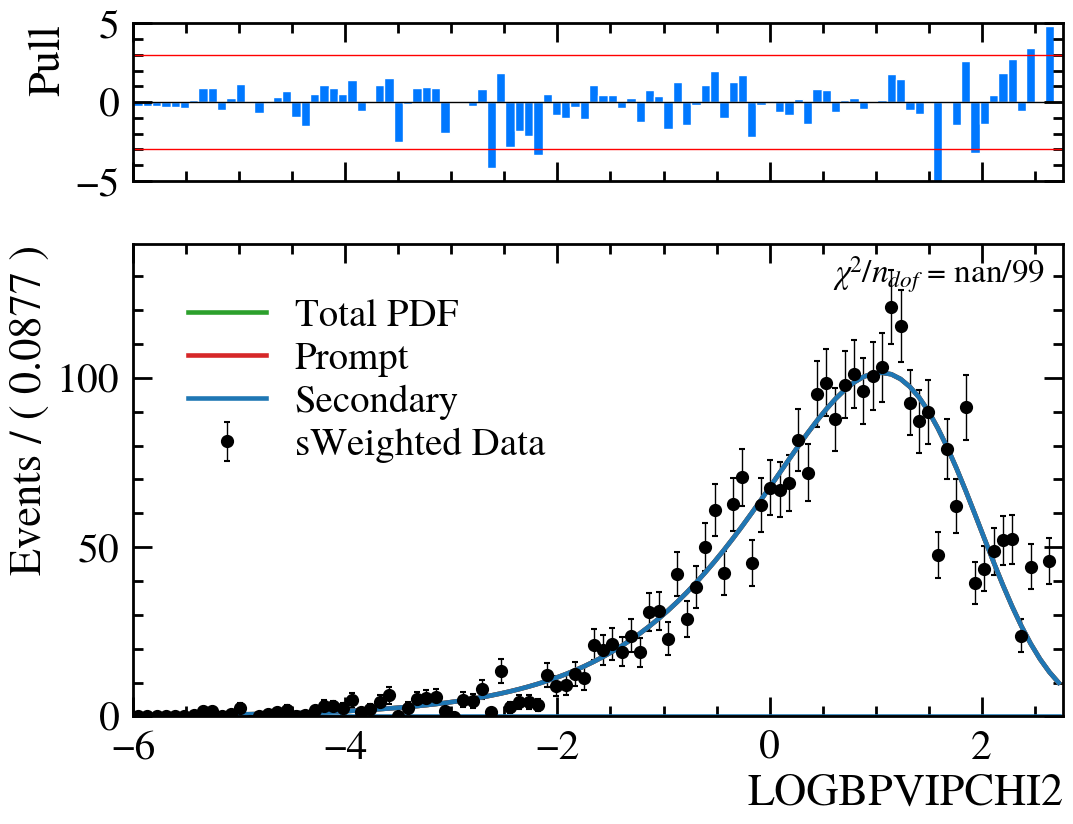

[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooRealVar::c_sigma_25_cut
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooRealVar::data_mu_P_25_cut
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooFormulaVar::data_lam_P_25_cut
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) using existing copy of RooRealVar::prompt_mc_sJsu for import of RooFormulaVar::data_lam_P_25_cut
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) using existing copy of RooRealVar::c_sigma_25_cut for import of RooFormulaVar::data_lam_P_25_cut
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooJohnson::pdf_prompt_data_25_cut
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) using existing copy of RooRealVar::Ds_LOGBPVIPCHI2 for import of RooJohnson::pdf_prompt_data_25_cut
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) using existing copy of RooRealVar::data_mu_P_25_cut for import of RooJohnson::pdf_prompt_data_25_cut
[#1] INFO:ObjectH

Info in <Minuit2>: MnSeedGenerator Computing seed using NumericalGradient calculator
Info in <Minuit2>: MnSeedGenerator Evaluated function and gradient in 15.0295 ms
Info in <Minuit2>: MnSeedGenerator Initial state: FCN =       4931.773989 Edm =       169.3809045 NCalls =     13
Info in <Minuit2>: MnSeedGenerator Initial state  
  Minimum value : 4931.773989
  Edm           : 169.3809045
  Internal parameters:	[    -0.3398369095     0.6987136938     0.5235987756]	
  Internal gradient  :	[     -390.8129172      850.2182927     -276.9079275]	
  Internal covariance matrix:
[[  0.00041699495              0              0]
 [              0  0.00032515475              0]
 [              0              0    0.004939996]]]
Info in <Minuit2>: VariableMetricBuilder Start iterating until Edm is < 0.001 with call limit = 1500
Info in <Minuit2>: VariableMetricBuilder    0 - FCN =       4931.773989 Edm =       169.3809045 NCalls =     13
Info in <Minuit2>: VariableMetricBuilder    1 - FCN =       4

In [ ]:
var_name = 'Ds_LOGBPVIPCHI2'
v_min, v_max_cut = -6.0, 2.77 
log_ip.setRange(-6.0, v_max_cut)
df_data_fit_25_cut = df_data_ds_25[(df_data_ds_25[var_name] >= v_min) & (df_data_ds_25[var_name] <= v_max_cut)]

#Dataset sWeighted
data_sweight_25_cut = r.RooDataSet("data_sweight_25_cut", "data_sweight_25_cut", 
                                   r.RooArgSet(log_ip, weight_var), r.RooFit.WeightVar("sWeight"))

for val, w in zip(df_data_fit_25_cut[var_name].values, df_data_fit_25_cut['sWeight'].values):
    log_ip.setVal(val)
    weight_var.setVal(w)
    data_sweight_25_cut.add(r.RooArgSet(log_ip, weight_var), w)

#free parameters
c_sigma_25_cut = add_to_workspace(ws_ip, r.RooRealVar("c_sigma_25_cut", "c_sigma_25_cut", 1.0, 0.5, 2.0))
data_mu_P_25_cut = add_to_workspace(ws_ip, r.RooRealVar("data_mu_P_25_cut", "data_mu_P_25_cut", 
                                                        ws_ip.var('prompt_mc_mJsu').getVal(), -2.0, 4.0))

#PDF Prompt
data_lam_P_25_cut = add_to_workspace(ws_ip, r.RooFormulaVar("data_lam_P_25_cut", "@0*@1",
                                                            r.RooArgList(ws_ip.var('prompt_mc_sJsu'), c_sigma_25_cut)))

pdf_prompt_data_25_cut = add_to_workspace(ws_ip, r.RooJohnson("pdf_prompt_data_25_cut", "Prompt Data 25 PDF (Cut)", 
                                                              log_ip, data_mu_P_25_cut, data_lam_P_25_cut, 
                                                              ws_ip.var('prompt_mc_gammaJsu'), ws_ip.var('prompt_mc_deltaJsu')))

#PDF Secondary 
data_mu_S_25_cut = add_to_workspace(ws_ip, r.RooFormulaVar("data_mu_S_25_cut", "@0+@1",
                                                           r.RooArgList(data_mu_P_25_cut, delta_mu)))

data_lam_S_25_cut = add_to_workspace(ws_ip, r.RooFormulaVar("data_lam_S_25_cut", "@0*@1", 
                                                            r.RooArgList(ws_ip.var('sec_mc_sJsu'), c_sigma_25_cut)))

pdf_sec_data_25_cut = add_to_workspace(ws_ip, r.RooJohnson("pdf_sec_data_25_cut", "Secondary Data 25 PDF (Cut)", 
                                                           log_ip, data_mu_S_25_cut, data_lam_S_25_cut, 
                                                           ws_ip.var('sec_mc_gammaJsu'), ws_ip.var('sec_mc_deltaJsu')))

#total model and fit
frac_prompt_data_25_cut = add_to_workspace(ws_ip, r.RooRealVar("frac_prompt_data_25_cut", "frac_prompt_data_25_cut", 0.75, 0.0, 1.0))
model_data_tot_25_cut = add_to_workspace(ws_ip, r.RooAddPdf("model_data_tot_25_cut", "Total Data 25 PDF (Cut)", 
                                                            [pdf_prompt_data_25_cut, pdf_sec_data_25_cut], [frac_prompt_data_25_cut]))

res_data_ip_25_cut = fu.fit_to_data(model_data_tot_25_cut, data_sweight_25_cut, kSilent=False)
res_data_ip_25_cut.Print()

#Plot
frame_data_25_cut = log_ip.frame(r.RooFit.Title("Fit LOGBPVIPCHI2 2025 (Cut 2.77)"))
data_sweight_25_cut.plotOn(frame_data_25_cut, r.RooFit.DataError(r.RooAbsData.SumW2))
model_data_tot_25_cut.plotOn(frame_data_25_cut, r.RooFit.LineColor(r.kGreen))
model_data_tot_25_cut.plotOn(frame_data_25_cut, r.RooFit.Components("pdf_prompt_data_25_cut"), r.RooFit.LineColor(r.kRed))
model_data_tot_25_cut.plotOn(frame_data_25_cut, r.RooFit.Components("pdf_sec_data_25_cut"), r.RooFit.LineColor(r.kBlue))
model_data_tot_25_cut.plotOn(frame_data_25_cut) 

fig_data_25_cut, ax_data_25_cut = fu.plot_fit_and_residuals_mpl(frame_data_25_cut, labels=['sWeighted Data', 'Total PDF', 'Prompt', 'Secondary'])

import matplotlib.ticker as ticker
fig_data_25_cut.axes[0].tick_params(axis='x', labelbottom=False)
fig_data_25_cut.axes[1].xaxis.set_major_formatter(ticker.ScalarFormatter())
fig_data_25_cut.axes[1].tick_params(axis='x', labelbottom=True)
plt.show()

Fit Result
Fit status = 0
Minuit status = 3
Number of Loops = 2
Real Time  = 1.6041350364685059
CPU Time  = 1.6000000000000014


/user/gr1/lhcb/limpicciche/tesi_impicciche/tesi-env/lib/python3.11/site-packages/analysis_helpers/fit.py:819: RuntimeWarning: invalid value encountered in sqrt
  mplhep.histplot(his,yerr=np.sqrt(his[0]),histtype='errorbar',color='black',label='data' if labels is None else labels[0],ax=ax2)
/user/gr1/lhcb/limpicciche/tesi_impicciche/tesi-env/lib/python3.11/site-packages/analysis_helpers/fit.py:759: RuntimeWarning: invalid value encountered in sqrt
  data_err = np.sqrt(data_counts) if poisson else np.sqrt(data_counts) # to be fixed


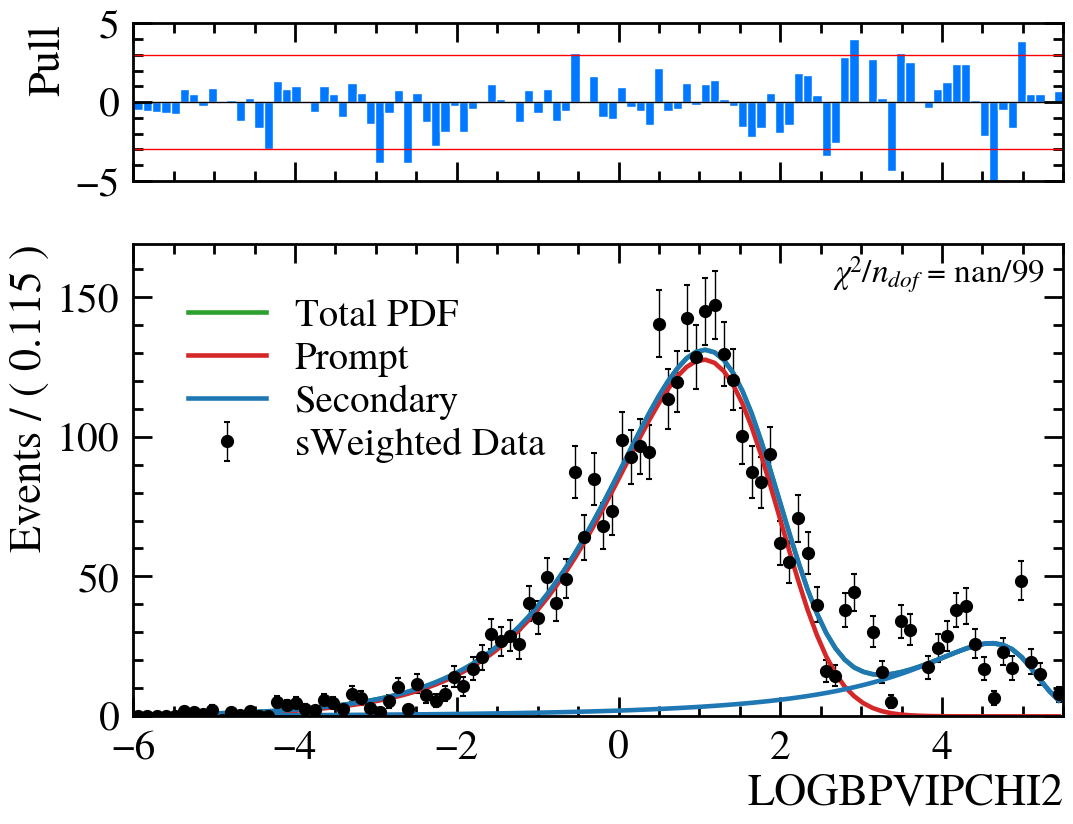

[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooRealVar::c_sigma_25_ext
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooRealVar::data_mu_P_25_ext
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooFormulaVar::data_lam_P_25_ext
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) using existing copy of RooRealVar::prompt_mc_sJsu for import of RooFormulaVar::data_lam_P_25_ext
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) using existing copy of RooRealVar::c_sigma_25_ext for import of RooFormulaVar::data_lam_P_25_ext
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooJohnson::pdf_prompt_data_25_ext
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) using existing copy of RooRealVar::Ds_LOGBPVIPCHI2 for import of RooJohnson::pdf_prompt_data_25_ext
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) using existing copy of RooRealVar::data_mu_P_25_ext for import of RooJohnson::pdf_prompt_data_25_ext
[#1] INFO:ObjectH

Info in <Minuit2>: MnSeedGenerator Computing seed using NumericalGradient calculator
Info in <Minuit2>: MnSeedGenerator Evaluated function and gradient in 58.1843 ms
Info in <Minuit2>: MnSeedGenerator Initial state: FCN =       6870.904751 Edm =       768.8594554 NCalls =     29
Info in <Minuit2>: MnSeedGenerator Initial state  
  Minimum value : 6870.904751
  Edm           : 768.8594554
  Internal parameters:	[    -0.3398369095    -0.8911225079                0    -0.3890508265     0.6987136938                0     0.5235987756]	
  Internal gradient  :	[     -38.21262297      264.8136823     -272.5912472     -185.0296685      182.9763686       135.906379     -839.7652379]	
  Internal covariance matrix:
[[  0.00038185694              0              0              0              0              0              0]
 [              0    0.021786166              0              0              0              0              0]
 [              0              0   0.0075480627              0       

In [ ]:
var_name = 'Ds_LOGBPVIPCHI2'
v_min, v_max_ext = -6.0, 5.5 
log_ip.setRange(-6.0, v_max_ext)
df_data_fit_25_ext = df_data_ds_25[(df_data_ds_25[var_name] >= v_min) & (df_data_ds_25[var_name] <= v_max_ext)]

#Dataset sWeighted
data_sweight_25_ext = r.RooDataSet("data_sweight_25_ext", "data_sweight_25_ext", 
                                   r.RooArgSet(log_ip, weight_var), r.RooFit.WeightVar("sWeight"))

for val, w in zip(df_data_fit_25_ext[var_name].values, df_data_fit_25_ext['sWeight'].values):
    log_ip.setVal(val)
    weight_var.setVal(w)
    data_sweight_25_ext.add(r.RooArgSet(log_ip, weight_var), w)

#PDF Prompt form MC 2024
c_sigma_25_ext = add_to_workspace(ws_ip, r.RooRealVar("c_sigma_25_ext", "c_sigma_25_ext", 1.0, 0.5, 2.0))
data_mu_P_25_ext = add_to_workspace(ws_ip, r.RooRealVar("data_mu_P_25_ext", "data_mu_P_25_ext", 
                                                        ws_ip.var('prompt_mc_mJsu').getVal(), -2.0, 4.0))

data_lam_P_25_ext = add_to_workspace(ws_ip, r.RooFormulaVar("data_lam_P_25_ext", "@0*@1",
                                                            r.RooArgList(ws_ip.var('prompt_mc_sJsu'), c_sigma_25_ext)))

pdf_prompt_data_25_ext = add_to_workspace(ws_ip, r.RooJohnson("pdf_prompt_data_25_ext", "Prompt Data 25 PDF (Ext)", 
                                                              log_ip, data_mu_P_25_ext, data_lam_P_25_ext, 
                                                              ws_ip.var('prompt_mc_gammaJsu'), ws_ip.var('prompt_mc_deltaJsu')))

#PDF Secondary indipendent from MC
data_mu_S_25_ext = add_to_workspace(ws_ip, r.RooRealVar("data_mu_S_25_ext", "mu Sec 25 Ext", 4.5, 3.0, 6.0))
data_lam_S_25_ext = add_to_workspace(ws_ip, r.RooRealVar("data_lam_S_25_ext", "lam Sec 25 Ext", 1.0, 0.1, 3.0))
data_gamma_S_25_ext = add_to_workspace(ws_ip, r.RooRealVar("data_gamma_S_25_ext", "gamma Sec 25 Ext", 0.0, -2.0, 2.0))
data_delta_S_25_ext = add_to_workspace(ws_ip, r.RooRealVar("data_delta_S_25_ext", "delta Sec 25 Ext", 1.0, 0.5, 5.0))

pdf_sec_data_25_ext = add_to_workspace(ws_ip, r.RooJohnson("pdf_sec_data_25_ext", "Secondary Data 25 PDF (Ext)", 
                                                           log_ip, data_mu_S_25_ext, data_lam_S_25_ext, 
                                                           data_gamma_S_25_ext, data_delta_S_25_ext))

#total model and fit
frac_prompt_data_25_ext = add_to_workspace(ws_ip, r.RooRealVar("frac_prompt_data_25_ext", "frac_prompt_data_25_ext", 0.75, 0.0, 1.0))
model_data_tot_25_ext = add_to_workspace(ws_ip, r.RooAddPdf("model_data_tot_25_ext", "Total Data 25 PDF (Ext)", 
                                                            [pdf_prompt_data_25_ext, pdf_sec_data_25_ext], [frac_prompt_data_25_ext]))

res_data_ip_25_ext = fu.fit_to_data(model_data_tot_25_ext, data_sweight_25_ext, kSilent=False)
res_data_ip_25_ext.Print()

#plot
frame_data_25_ext = log_ip.frame(r.RooFit.Title("Fit LOGBPVIPCHI2 2025 (Extended)"))
data_sweight_25_ext.plotOn(frame_data_25_ext, r.RooFit.DataError(r.RooAbsData.SumW2))
model_data_tot_25_ext.plotOn(frame_data_25_ext, r.RooFit.LineColor(r.kGreen))
model_data_tot_25_ext.plotOn(frame_data_25_ext, r.RooFit.Components("pdf_prompt_data_25_ext"), r.RooFit.LineColor(r.kRed))
model_data_tot_25_ext.plotOn(frame_data_25_ext, r.RooFit.Components("pdf_sec_data_25_ext"), r.RooFit.LineColor(r.kBlue))
model_data_tot_25_ext.plotOn(frame_data_25_ext) 

fig_data_25_ext, ax_data_25_ext = fu.plot_fit_and_residuals_mpl(frame_data_25_ext, labels=['sWeighted Data', 'Total PDF', 'Prompt', 'Secondary'])

import matplotlib.ticker as ticker
fig_data_25_ext.axes[0].tick_params(axis='x', labelbottom=False)
fig_data_25_ext.axes[1].xaxis.set_major_formatter(ticker.ScalarFormatter())
fig_data_25_ext.axes[1].tick_params(axis='x', labelbottom=True)
plt.show()

# Check

In [ ]:
#check
n_prompt = len(df_MC_ds[df_MC_ds['is_prompt'] == 1])
n_sec = len(df_MC_ds[df_MC_ds['is_prompt'] == 0])
print(n_prompt)
print(n_sec)

frac_sec = n_sec / (n_prompt + n_sec) * 100
print(frac_sec)

43416
31338
41.9215025282928


In [12]:
print(df_MC_ds['Ds_LOGBPVIPCHI2'].max())
print(df_data_ds['Ds_LOGBPVIPCHI2'].max())

4.5909395
6.219424


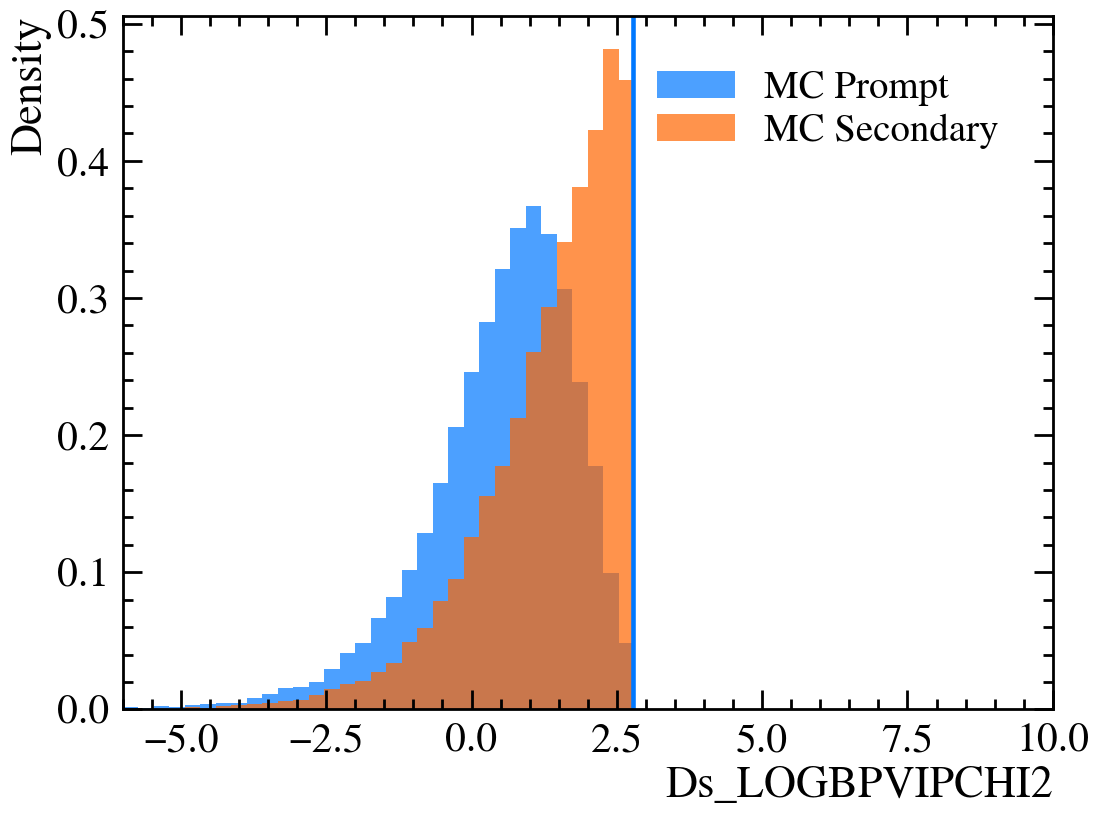

In [13]:
plt.hist(df_MC_ds.loc[df_MC_ds['is_prompt'] == 1, 'Ds_LOGBPVIPCHI2'], bins=60, range=(-6, 10), density=True, alpha=0.7,label='MC Prompt ')
plt.hist(df_MC_ds.loc[df_MC_ds['is_prompt'] == 0, 'Ds_LOGBPVIPCHI2'], bins=60, range=(-6, 10), density=True, alpha=0.7, label='MC Secondary')
plt.axvline(x=np.log(16))
plt.xlabel('Ds_LOGBPVIPCHI2')
plt.ylabel('Density')
plt.legend()
plt.show()

In [14]:
th = np.log(16) 
sup_th= df_MC_ds[df_MC_ds['Ds_LOGBPVIPCHI2'] > th]

print(len(sup_th))
print(len(df_MC_ds))

39
74754
